# NHANES exploratory data analysis

This notebook builds the study cohort from the raw NHANES 2017-March 2020 files, creates the CKD label, checks data quality, and explores the Tier 3 features. Every rule used here was written down beforehand in `documentation/preregistration.md`.

It works in this order:

1. **Data quality checks on the whole cohort.** These only apply fixed rules (answer codes, skip patterns, plausible ranges), so nothing is learned from the data that could leak into the test set.
2. **The 80/20 train/test split.**
3. **Distributions and relationships with the label, on the training set only.** The test set is not looked at anywhere in this notebook.

Output: `data/processed/nhanes_cohort.csv`, which the modeling notebook reads. Figures are also saved to `documentation/figures/` for the paper.

Run it from the `notebooks/` folder. VS Code does this by default.

## 1. Setup

The cleaning code lives in `src/nhanes.py` so the modeling notebook and the app use exactly the same rules. `src/plot_style.py` only sets the colors and fonts for the charts.

Two colors are used for the classes in every figure: **blue = no CKD, orange = CKD**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# the notebook runs from notebooks/, so the project root is one folder up
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

import nhanes
import plot_style

plot_style.apply()

NHANES_DIR = PROJECT_ROOT / "data" / "original" / "nhanes"
FIGURE_DIR = PROJECT_ROOT / "documentation" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 2. Raw files: size and duplicate IDs

Each NHANES component is a separate file, and all of them share the participant ID `SEQN`. Before joining them I check how big each file is and whether any `SEQN` appears twice in the same file. A duplicated ID would make the join create extra rows for that person.

**What to look at:** the `duplicate SEQN` column should be 0 for every file.

In [2]:
rows = []
for name in nhanes.RAW_FILES:
    table = pd.read_sas(NHANES_DIR / f"{name}.xpt", format="xport")
    rows.append({
        "file": name,
        "rows": table.shape[0],
        "columns": table.shape[1],
        "duplicate SEQN": table["SEQN"].duplicated().sum(),
    })
pd.DataFrame(rows)

,file,rows,columns,duplicate SEQN
0,P_DEMO,15560,29,0
1,P_BMX,14300,22,0
2,P_BPXO,11656,12,0
3,P_BPQ,10195,11,0
4,P_DIQ,14986,28,0
5,P_SMQ,11137,16,0
6,P_MCQ,14986,63,0
7,P_KIQ_U,9232,16,0
8,P_BIOPRO,10409,41,0
9,P_ALB_CR,13027,8,0


**Finding:** The 10 files have between 9,232 and 15,560 rows. They differ because each part of the survey has its own age range and not everyone completed every part. For example, the kidney questionnaire (P_KIQ_U) has 9,232 rows, exactly the number of participants aged 20 and over, because it is only asked to adults. No file has a duplicated SEQN, so every join matches one row to one row.

**Action:** none needed.

## 3. Building the cohort

- `load_raw` joins the columns I need from all 10 files onto the demographics file.
- `replace_refused_and_dont_know` turns answer codes 7 (refused) and 9 (don't know) into missing values. Section 5.2 shows why.
- `build_cohort` applies the five inclusion rules from the pre-registration, in order, and records how many people each rule removed.

**What to look at:** the `removed` column. Each rule should only remove people, and the last row is the size of the dataset everything else is built on.

In [3]:
raw_with_codes = nhanes.load_raw(NHANES_DIR)   # still has the 7 / 9 codes, used again in section 5.2
raw = nhanes.replace_refused_and_dont_know(raw_with_codes)

cohort, flow = nhanes.build_cohort(raw)
flow

,step,remaining,removed
0,All participants,15560,0
1,Age 20 or older,9232,6328
2,Examined at the mobile exam center,8544,688
3,Not pregnant,8457,87
4,Has serum creatinine and urine ACR,7667,790
5,"Not told of weak or failing kidneys, no dialysis",7363,304


**Finding:** Out of 15,560 participants, 7,363 adults are in the final cohort.

- 6,328 were under 20.
- 688 adults were only interviewed and never went to the exam center, so they have no measurements at all.
- 87 pregnant women were removed.
- 790 adults had no creatinine or no urine ACR result, so their label cannot be built.
- 304 had already been told they have weak or failing kidneys. The dialysis question is only asked to people who answered yes to that question, so all dialysis patients were inside this group.

**Action:** these 7,363 people are the dataset for everything that follows.

### 3.1 Were the people without lab results different?

This check was pre-registered. If the people dropped for missing lab results were very different from the people kept (for example, much sicker), the cohort would be biased.

**What to look at:** whether the two rows are close. Values are means, so `diabetes = 0.15` means 15 percent.

In [4]:
# everyone who passed the first three rules, before the lab rule
before_lab_rule = raw[(raw["RIDAGEYR"] >= 20) & (raw["RIDSTATR"] == 2) & (raw["RIDEXPRG"] != 1)]
no_labs = before_lab_rule["LBXSCR"].isna() | before_lab_rule["URDACT"].isna()

check = pd.DataFrame({
    "no_labs": no_labs,
    "age": before_lab_rule["RIDAGEYR"],
    "diabetes": before_lab_rule["DIQ010"] == 1,
    "told_hypertension": before_lab_rule["BPQ020"] == 1,
    "female": before_lab_rule["RIAGENDR"] == 2,
})
summary = check.groupby("no_labs").mean()
summary["people"] = check["no_labs"].value_counts()
summary.rename(index={False: "kept", True: "dropped (no labs)"}).round(3)

,age,diabetes,told_hypertension,female,people
no_labs,,,,,
kept,51.021,0.154,0.385,0.512,7667
dropped (no labs),53.082,0.176,0.432,0.503,790


**Finding:** The 790 people without lab results were slightly older (53.1 vs 51.0 years) and had a bit more diabetes (17.6% vs 15.4%) and hypertension (43.2% vs 38.5%). The share of women is about the same. The differences are small, but they all point the same way: the dropped group was slightly higher risk.

**Action:** the method does not change. I note it as a limitation: the CKD prevalence in my cohort is probably slightly lower than in the full adult population.

## 4. The CKD label

CKD = 1 if **eGFR < 60** or **urine albumin-to-creatinine ratio (ACR) >= 30 mg/g**.

eGFR is calculated from serum creatinine, age and sex with the CKD-EPI 2021 equation (the function `egfr_ckd_epi_2021` in `src/nhanes.py`). Before trusting the function I test it on an example I worked out by hand: a 60 year old man with creatinine 1.4 mg/dL should get about **57.5**.

**What to look at:** the printed eGFR should be 57.5. If it is not, the function has a mistake and every label after this would be wrong.

The crosstab shows how many people are labeled CKD because of low eGFR, because of albuminuria, or both.

In [5]:
example = nhanes.egfr_ckd_epi_2021(pd.Series([1.4]), pd.Series([60]), pd.Series([False]))
print(f"Hand-checked example: {example[0]:.1f}")

cohort = nhanes.add_label(cohort)
print(f"CKD cases: {cohort['ckd'].sum()} of {len(cohort)} ({cohort['ckd'].mean():.1%})")
print(f"eGFR below 15: {(cohort['egfr'] < 15).sum()}, ACR 3000 or more: {(cohort['URDACT'] >= 3000).sum()}")

pd.crosstab(cohort["low_egfr"], cohort["albuminuria"], margins=True)

Hand-checked example: 57.5
CKD cases: 1217 of 7363 (16.5%)
eGFR below 15: 3, ACR 3000 or more: 7


albuminuria,0,1,All
low_egfr,,,
0,6146,766,6912
1,302,149,451
All,6448,915,7363


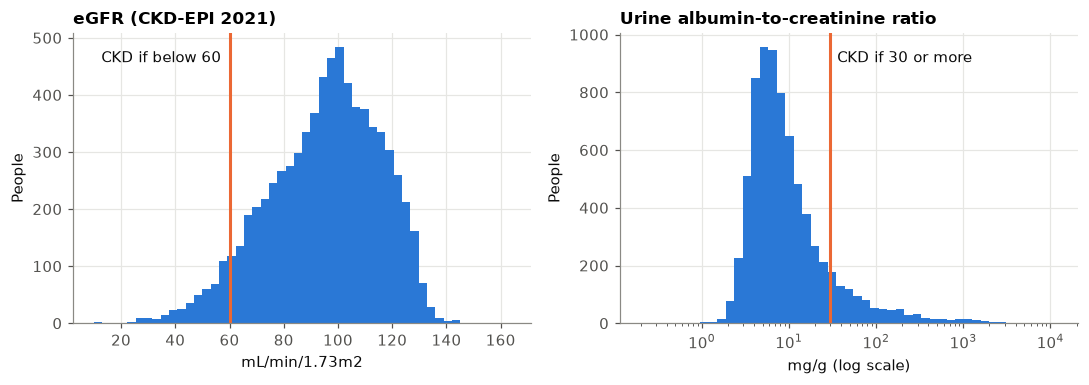

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

axes[0].hist(cohort["egfr"], bins=50, color=plot_style.NO_CKD)
axes[0].axvline(60, color=plot_style.CKD, linewidth=2)
axes[0].text(57, axes[0].get_ylim()[1] * 0.9, "CKD if below 60", ha="right", color=plot_style.TEXT)
axes[0].set(title="eGFR (CKD-EPI 2021)", xlabel="mL/min/1.73m2", ylabel="People")

# ACR is very skewed, so the bins are spaced evenly on a log scale
log_bins = np.logspace(np.log10(0.2), np.log10(12000), 50)
axes[1].hist(cohort["URDACT"], bins=log_bins, color=plot_style.NO_CKD)
axes[1].axvline(30, color=plot_style.CKD, linewidth=2)
axes[1].text(36, axes[1].get_ylim()[1] * 0.9, "CKD if 30 or more", color=plot_style.TEXT)
axes[1].set_xscale("log")
axes[1].set(title="Urine albumin-to-creatinine ratio", xlabel="mg/g (log scale)", ylabel="People")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_01_label.png")
plt.show()

**Finding:** The hand-checked example gives 57.5, so the eGFR function is correct. 1,217 of 7,363 adults (16.5%) are labeled CKD:

- 766 only because of albuminuria
- 302 only because of low eGFR
- 149 because of both

So most of the CKD in this population is early disease that shows up in the urine before kidney function drops. That is the stage where screening helps the most. It is also the part of the label most affected by the single-measurement limitation, because albuminuria can be temporary.

The ACR is very right-skewed (median 7.4 mg/g, highest 11,677 mg/g), which is why it is plotted on a log scale. At the extreme end, 3 people have an eGFR below 15 (the level of kidney failure) and 7 have an ACR of 3,000 mg/g or more, and none of them had ever been told they have kidney disease. These are real, very sick people, not data errors, and they are exactly the kind of missed patient this project is about.

**Action:** keep all of them. The label values are never model inputs, so extreme values here cannot distort the model directly.

## 5. Data quality

### 5.1 Features, data types and units

`build_features` turns the raw NHANES columns into the 13 Tier 3 features. This table is the data dictionary for them.

**What to look at:** the numeric features should be `float64`, the yes/no features should only contain 0 and 1, and the two categorical features should be text.

In [7]:
features = nhanes.build_features(cohort)

dictionary = pd.DataFrame(nhanes.FEATURE_INFO, index=["source", "unit or coding", "meaning"]).T
dictionary["dtype"] = features.dtypes.astype(str)
dictionary["values seen"] = [
    f"{features[c].min():.1f} to {features[c].max():.1f}" if c in nhanes.NUMERIC_FEATURES
    else ", ".join(str(v) for v in sorted(features[c].dropna().unique()))
    for c in dictionary.index
]
dictionary

,source,unit or coding,meaning,dtype,values seen
age,RIDAGEYR,years,Age at screening. 80 means 80 or older.,float64,20.0 to 80.0
bmi,BMXBMI,kg/m2,Body mass index,float64,14.2 to 92.3
waist,BMXWAIST,cm,Waist circumference,float64,57.9 to 178.0
sbp,BPXOSY1-3,mmHg,"Systolic blood pressure, mean of up to 3 readings",float64,76.3 to 218.7
dbp,BPXODI1-3,mmHg,"Diastolic blood pressure, mean of up to 3 read...",float64,41.3 to 135.0
female,RIAGENDR,"1 = female, 0 = male",Sex,int64,"0, 1"
told_htn,BPQ020,"1 = yes, 0 = no",Ever told by a doctor they have high blood pre...,float64,"0.0, 1.0"
bp_meds,"BPQ040A, BPQ050A","1 = yes, 0 = no",Currently taking prescribed blood pressure med...,float64,"0.0, 1.0"
high_chol,BPQ080,"1 = yes, 0 = no",Ever told by a doctor they have high cholesterol,float64,"0.0, 1.0"
any_cvd,MCQ160B-F,"1 = yes, 0 = no","Ever told they had heart failure, coronary hea...",float64,"0.0, 1.0"


**Finding:** There are 13 features: 5 numeric measurements, 6 yes/no features coded 1 and 0, and 2 categorical features stored as text. Blood pressure values are averages of up to three readings, which is why they are not whole numbers. The yes/no features are stored as decimals only because they can contain missing values. Every feature contains only the values I expected.

**Action:** none. In the pipeline, numeric features will be filled in and scaled, yes/no features will be filled in, and the two text features will be filled in and one-hot encoded.

### 5.2 Refused and "don't know" answers

In NHANES questionnaires, 1 = yes and 2 = no, but 7 = refused and 9 = don't know. Those last two are not real answers. If they were left in, a "don't know" (9) would look like a very large value of a yes/no question.

**What to look at:** how many answers in the cohort used these codes, before they were replaced.

In [8]:
in_cohort = raw_with_codes["SEQN"].isin(cohort["SEQN"])
codes = raw_with_codes.loc[in_cohort, nhanes.QUESTION_COLUMNS]
codes.isin([7, 9]).sum().to_frame("answers coded 7 or 9").T

,BPQ020,BPQ040A,BPQ050A,BPQ080,DIQ010,SMQ020,SMQ040,MCQ160B,MCQ160C,MCQ160D,MCQ160E,MCQ160F,MCQ300C,KIQ022,KIQ025
answers coded 7 or 9,11,3,0,42,3,3,0,14,22,29,11,9,102,13,0


**Finding:** Family history of diabetes (MCQ300C) has by far the most, with 102 people (1.4% of the cohort) who did not know the answer. Every other question has 42 or fewer, and three have none.

**Action:** these were already replaced with missing values in section 3, and they are filled in later inside the model pipeline. "Don't know" is also a realistic answer at a health unit, especially for family history, so the app will accept it and handle it the same way.

### 5.3 Skip patterns: a blank that is not really missing

Some questions are only asked depending on an earlier answer. For example, "Do you now smoke cigarettes?" (`SMQ040`) is only asked if the person said yes to "Have you smoked at least 100 cigarettes in your life?" (`SMQ020`). So a never smoker has a blank `SMQ040`, but I already know their answer: they do not smoke now.

Treating these blanks as missing and filling them in with a guess would be wrong. In the tables below, -1 stands for a blank.

**What to look at:** the blanks in the second question should line up exactly with "no" (2) in the first question.

In [9]:
blank = -1
print("Smoked 100 cigarettes (rows) vs smokes now (columns)")
print(pd.crosstab(cohort["SMQ020"].fillna(blank), cohort["SMQ040"].fillna(blank)))

print("\nTold to take BP medicine (rows) vs taking it now (columns)")
print(pd.crosstab(cohort["BPQ040A"].fillna(blank), cohort["BPQ050A"].fillna(blank)))

Smoked 100 cigarettes (rows) vs smokes now (columns)
SMQ040  -1.0   1.0   2.0   3.0
SMQ020                        
-1.0       3     0     0     0
 1.0       0  1037   293  1720
 2.0    4310     0     0     0

Told to take BP medicine (rows) vs taking it now (columns)
BPQ050A  -1.0   1.0   2.0
BPQ040A                  
-1.0     4637     0     0
 1.0        0  2108   379
 2.0      239     0     0


**Finding:** The blanks line up exactly with the skip pattern.

- All 4,310 blanks in "smokes now" belong to people who said they never smoked 100 cigarettes. The 3 people blank in both smoking questions refused or did not know, so they really are missing.
- All 239 blanks in "taking BP medicine now" among people who answered the earlier question belong to people who were never told to take medicine. Most of the 4,637 people blank in both questions (4,623) were never told they have high blood pressure, so neither question was asked.

**Action:** `smoking_status` and `bp_medication` in `src/nhanes.py` read these blanks as "never smoker" and "not taking BP medicine" instead of missing. Without this, smoking would have been missing for 4,310 people (about 59% of the cohort), and the pipeline would have had to guess an answer that is already known.

### 5.4 Duplicates and inconsistent entries

- A participant ID appearing twice would mean the same person is counted twice.
- Two rows with identical features are not a problem by themselves if they belong to different people, but it is worth knowing how many there are.
- An inconsistent entry would be someone taking blood pressure medicine who was never told they have high blood pressure.

In [10]:
print("Duplicate participant IDs:", cohort["SEQN"].duplicated().sum())
print("Rows with exactly the same 13 feature values:", features.duplicated().sum())
print("Taking BP medicine but never told of high BP:",
      ((features["bp_meds"] == 1) & (features["told_htn"] == 0)).sum())

Duplicate participant IDs: 0
Rows with exactly the same 13 feature values: 2
Taking BP medicine but never told of high BP: 0


**Finding:** No participant ID appears twice. Two rows have exactly the same 13 feature values as another row, but they belong to different participants, so they are different people who happen to match, not repeated records. Nobody is taking BP medicine without having been told they have high blood pressure.

**Action:** none needed.

### 5.5 Impossible values

For each numeric feature I set a range that a living adult could realistically have (`PLAUSIBLE_RANGES` in `src/nhanes.py`). These ranges are wide on purpose. They are meant to catch entry errors such as a BMI of 0 or a blood pressure of 999, not unusual but real people.

**What to look at:** the `below` and `above` columns. Anything there would be a data error that needs fixing.

In [11]:
rows = []
for column, (low, high) in nhanes.PLAUSIBLE_RANGES.items():
    rows.append({
        "feature": column,
        "allowed range": f"{low} to {high}",
        "actual min": features[column].min(),
        "actual max": features[column].max(),
        "below": (features[column] < low).sum(),
        "above": (features[column] > high).sum(),
    })
pd.DataFrame(rows).round(1)

,feature,allowed range,actual min,actual max,below,above
0,age,20 to 80,20.0,80.0,0,0
1,bmi,10 to 100,14.2,92.3,0,0
2,waist,40 to 200,57.9,178.0,0,0
3,sbp,60 to 260,76.3,218.7,0,0
4,dbp,30 to 150,41.3,135.0,0,0


**Finding:** No value is outside its plausible range, so there are no data entry errors in the numeric features. The most unusual values are a BMI of 92.3 and a systolic blood pressure of 218.7 mmHg. Both are rare but possible (severe obesity and a hypertensive crisis). They are looked at again in section 11.

**Action:** none. The same ranges will be reused in the app to reject impossible inputs.

### 5.6 Missing values

After recoding, the remaining missing values are real gaps: a measurement that was not taken or a question that was not answered.

**What to look at:** which features have the most missing values. Anything above roughly 30 percent would need a decision about dropping the feature.

In [12]:
missing = features.isna().sum().to_frame("missing")
missing["percent"] = (missing["missing"] / len(features) * 100).round(1)
missing.sort_values("missing", ascending=False)

,missing,percent
dbp,661,9.0
sbp,661,9.0
waist,271,3.7
fam_diabetes,102,1.4
bmi,75,1.0
any_cvd,42,0.6
high_chol,42,0.6
bp_meds,14,0.2
told_htn,11,0.1
smoking,3,0.0


**Finding:** Blood pressure is missing for 661 people (9.0%) and waist for 271 (3.7%). Everything else is under 1.5%. No feature is anywhere near the point where dropping it would make sense.

**Action:** keep every feature and fill in missing values inside the model pipeline: the median for numeric features and the most common answer for yes/no and categorical features. Because this happens inside the pipeline, the fill values are learned only from the training folds. Section 13 checks whether a missing value carries information by itself.

## 6. Train/test split

The label and features now exist, so the data can be split. The split is 80/20, stratified on the CKD label so both parts have the same share of CKD cases, with `random_state = 42` so it comes out the same every time (`add_split` in `src/nhanes.py`).

The whole cohort is saved with a `split` column. Saving it once means the modeling notebook uses exactly this split instead of making a new one.

**From this point on, everything uses the training rows only.**

In [13]:
keep = ["SEQN", "RIDRETH3", "egfr", "URDACT", "low_egfr", "albuminuria", "ckd"]
data = pd.concat([cohort[keep], features], axis=1)
data = nhanes.add_split(data)

data.to_csv(PROJECT_ROOT / "data" / "processed" / "nhanes_cohort.csv", index=False)

train = data[data["split"] == "train"].copy()
data.groupby("split")["ckd"].agg(people="size", ckd_cases="sum", prevalence="mean").round(4)

,people,ckd_cases,prevalence
split,,,
test,1473,243,0.1650
train,5890,974,0.1654


**Finding:** 5,890 people are in the training set and 1,473 in the test set. The CKD share is 16.5% in both, so the stratification worked.

**Action:** from here on only the training rows are used. The saved file also contains `egfr`, `URDACT`, `low_egfr` and `albuminuria` for analysis, but the modeling code only selects the 13 columns in `nhanes.FEATURES`, so the label columns can never become inputs.

## 7. Class distribution

**What to look at:** how unbalanced the two classes are, and how the share of CKD changes with age.

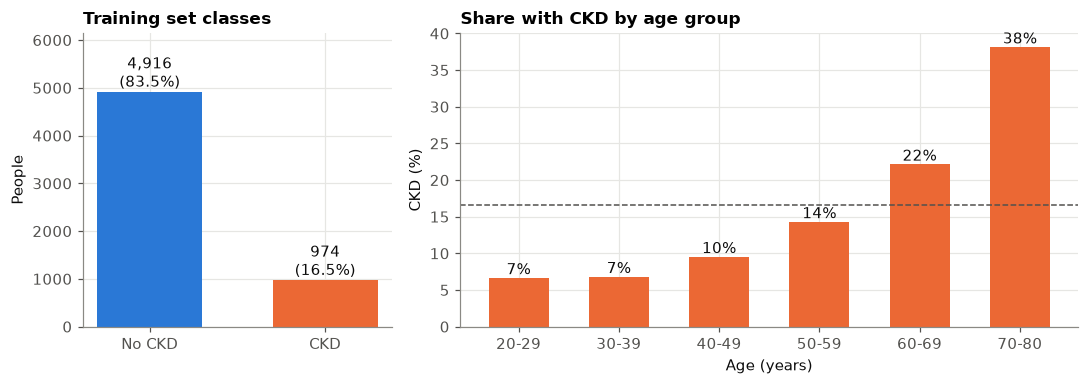

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [1, 2]})

counts = train["ckd"].value_counts().sort_index()
bars = axes[0].bar(["No CKD", "CKD"], counts.values, color=[plot_style.NO_CKD, plot_style.CKD], width=0.6)
for bar, n in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, n, f"{n:,}\n({n / counts.sum():.1%})",
                 ha="center", va="bottom", color=plot_style.TEXT)
axes[0].set(title="Training set classes", ylabel="People", ylim=(0, counts.max() * 1.25))

age_band = pd.cut(train["age"], bins=[19, 29, 39, 49, 59, 69, 80],
                  labels=["20-29", "30-39", "40-49", "50-59", "60-69", "70-80"])
by_age = train.groupby(age_band, observed=True)["ckd"].mean()
bars = axes[1].bar(by_age.index.astype(str), by_age.values * 100, color=plot_style.CKD, width=0.6)
for bar, rate in zip(bars, by_age.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, rate * 100, f"{rate:.0%}",
                 ha="center", va="bottom", color=plot_style.TEXT)
axes[1].axhline(train["ckd"].mean() * 100, color=plot_style.TEXT_SECONDARY, linestyle="--", linewidth=1)
axes[1].set(title="Share with CKD by age group", xlabel="Age (years)", ylabel="CKD (%)")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_02_classes.png")
plt.show()

**Finding:** The training set has 4,916 people without CKD and 974 with CKD (16.5%), about 5 to 1. A model that always says "no CKD" would already be 83.5% accurate while missing every single patient, which is why accuracy is not my main metric. CKD also rises steeply with age: 7% in people in their 20s and 30s, 14% in their 50s, and 38% at 70 and over.

**Action:** this supports the pre-registered choices: F2 as the primary metric, `class_weight="balanced"` in all three models, and stratified folds. With a prevalence of 16.5%, the refer-everyone baseline has F2 = 5(0.165) / (4(0.165) + 1) = 0.50, so a useful model has to score above 0.50.

## 8. Numeric features

Summary statistics first, then the distribution of each numeric feature drawn separately for people with and without CKD. Each curve is scaled to its own group size (density), so the much smaller CKD group can still be compared by shape.

**What to look at:** how far apart the blue and orange curves are. The more they are shifted, the more that feature separates the classes on its own.

In [15]:
stats = train[nhanes.NUMERIC_FEATURES].describe().T
stats["skew"] = train[nhanes.NUMERIC_FEATURES].skew()
stats["median no CKD"] = train.loc[train["ckd"] == 0, nhanes.NUMERIC_FEATURES].median()
stats["median CKD"] = train.loc[train["ckd"] == 1, nhanes.NUMERIC_FEATURES].median()
stats.round(1)

,count,mean,std,min,25%,50%,75%,max,skew,median no CKD,median CKD
age,5890.0,50.5,17.3,20.0,36.0,51.0,64.0,80.0,-0.0,48.0,64.0
bmi,5828.0,30.0,7.5,14.2,24.8,28.7,33.8,92.3,1.3,28.6,29.9
waist,5678.0,100.8,17.1,62.7,88.8,99.3,111.5,178.0,0.5,98.5,103.5
sbp,5360.0,124.4,18.7,76.3,110.7,122.0,135.0,218.7,0.8,120.3,130.3
dbp,5360.0,74.7,11.3,41.3,67.0,74.0,81.7,135.0,0.5,74.0,74.0


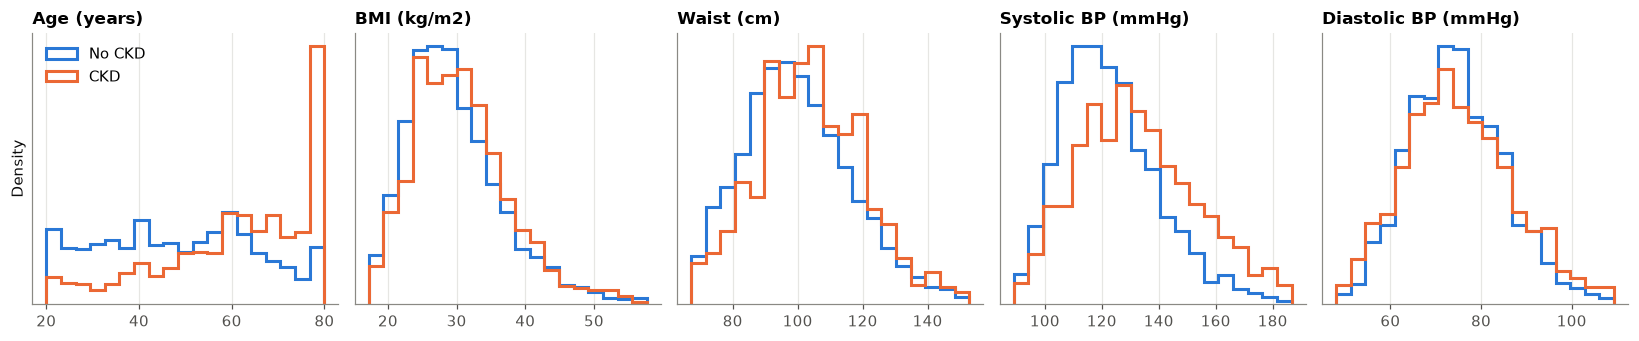

In [16]:
titles = {"age": "Age (years)", "bmi": "BMI (kg/m2)", "waist": "Waist (cm)",
          "sbp": "Systolic BP (mmHg)", "dbp": "Diastolic BP (mmHg)"}

fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, column in zip(axes, nhanes.NUMERIC_FEATURES):
    values = train[column].dropna()
    bins = np.linspace(values.quantile(0.005), values.quantile(0.995), 20)
    for label, color, name in [(0, plot_style.NO_CKD, "No CKD"), (1, plot_style.CKD, "CKD")]:
        ax.hist(train.loc[train["ckd"] == label, column].dropna(), bins=bins, density=True,
                histtype="step", linewidth=2, color=color, label=name)
    ax.set(title=titles[column], yticks=[])
axes[0].set_ylabel("Density")
axes[0].legend(loc="upper left")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_03_numeric.png")
plt.show()

**Finding:** Age separates the classes the most: the median age is 64 with CKD and 48 without. The spike at 80 is the top-coding (everyone 80 or older is recorded as 80). The orange spike is much taller because half of the people in that group have CKD. Systolic BP is also clearly higher with CKD (median 130.3 vs 120.3 mmHg). BMI and waist are only a little higher (29.9 vs 28.6, and 103.5 vs 98.5 cm). Diastolic BP shows no difference at all: the median is 74.0 in both groups. BMI is the most skewed feature (skew 1.3), with a long tail of high values.

**Action:** keep all five, as pre-registered. Diastolic BP stays even though it does not separate the classes by itself, because with age systolic BP rises while diastolic does not (section 10), so the two together may carry information that each one alone does not. The pipeline scales numeric features, which Logistic Regression needs and the tree models ignore. I do not log-transform BMI because its skew is moderate.

## 9. Yes/no and categorical features against the label

For each answer, the bar shows what share of people with that answer have CKD. The dashed line is the overall share. A feature is useful when its bars sit far from the line in opposite directions.

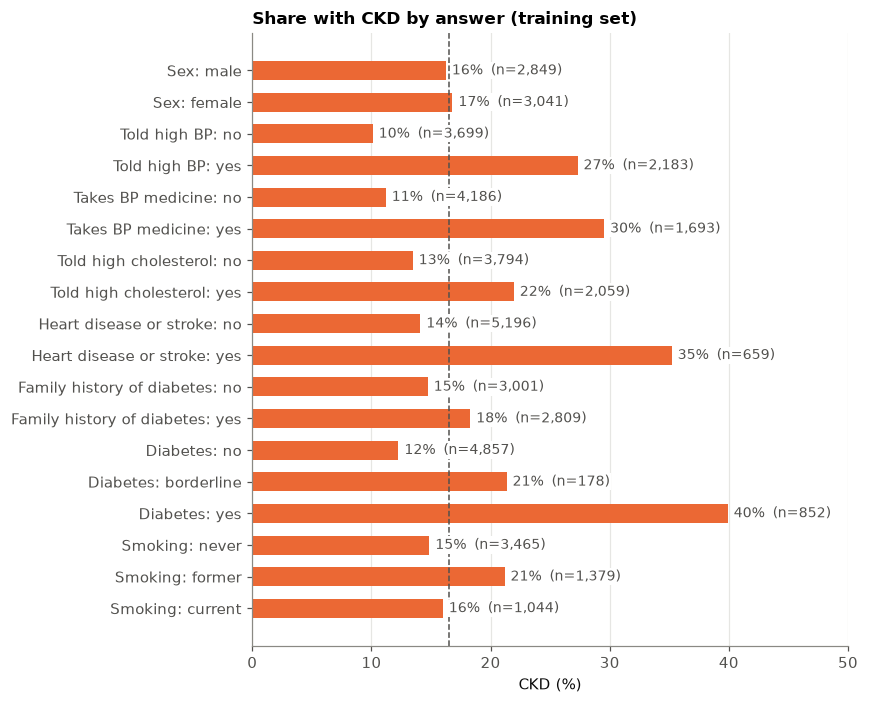

,feature,answer,people,ckd_rate
0,Sex,male,2849,0.163
1,Sex,female,3041,0.168
2,Told high BP,no,3699,0.101
3,Told high BP,yes,2183,0.273
4,Takes BP medicine,no,4186,0.112
5,Takes BP medicine,yes,1693,0.295
6,Told high cholesterol,no,3794,0.135
7,Told high cholesterol,yes,2059,0.220
8,Heart disease or stroke,no,5196,0.141
9,Heart disease or stroke,yes,659,0.352


In [17]:
names = {"female": "Sex", "told_htn": "Told high BP", "bp_meds": "Takes BP medicine",
         "high_chol": "Told high cholesterol", "any_cvd": "Heart disease or stroke",
         "fam_diabetes": "Family history of diabetes", "diabetes": "Diabetes", "smoking": "Smoking"}
# the order the answers are shown in, and how each one is labeled
levels = {"female": {0: "male", 1: "female"},
          "diabetes": {"no": "no", "borderline": "borderline", "yes": "yes"},
          "smoking": {"never": "never", "former": "former", "current": "current"}}

rows = []
for column in nhanes.BINARY_FEATURES + nhanes.CATEGORICAL_FEATURES:
    for value, shown in levels.get(column, {0: "no", 1: "yes"}).items():
        group = train[train[column] == value]
        rows.append({"feature": names[column], "answer": shown,
                     "people": len(group), "ckd_rate": group["ckd"].mean()})
rates = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 6.5))
y_labels = rates["feature"] + ": " + rates["answer"]
positions = np.arange(len(rates))[::-1]
ax.barh(positions, rates["ckd_rate"] * 100, color=plot_style.CKD, height=0.6)
for y, row in zip(positions, rates.itertuples()):
    ax.text(row.ckd_rate * 100 + 0.5, y, f"{row.ckd_rate:.0%}  (n={row.people:,})",
            va="center", color=plot_style.TEXT_SECONDARY, fontsize=9,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.axvline(train["ckd"].mean() * 100, color=plot_style.TEXT_SECONDARY, linestyle="--", linewidth=1)
ax.set_yticks(positions, y_labels)
ax.set(title="Share with CKD by answer (training set)", xlabel="CKD (%)", xlim=(0, 50))
ax.grid(axis="y", visible=False)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_04_categorical.png")
plt.show()

rates.round(3)

**Finding:** Diabetes is the strongest: 40% of people with diabetes have CKD, compared with 12% of people without it. Borderline diabetes sits in between at 21%, so keeping it as its own category instead of merging it into yes or no was the right call. Heart disease or stroke (35% vs 14%), being told of high BP (27% vs 10%) and taking BP medicine (30% vs 11%) are also strong. High cholesterol and family history of diabetes have smaller effects. Sex makes almost no difference (16% vs 17%).

**Action:** keep all of them, as pre-registered. Sex stays in even though it is flat here, because it is part of the eGFR equation and may matter in combination with age.

The smoking result needs one more check. Former smokers having more CKD than current smokers could be because former smokers are older, since people tend to quit later in life.

In [18]:
train.groupby("smoking")["age"].median().to_frame("median age")

,median age
smoking,
current,48.0
former,61.0
never,49.0


**Finding:** Former smokers are much older (median 61) than current smokers (48) and never smokers (49). So their higher CKD rate is most likely about age, not about having quit. This is confounding: one feature looks important only because it travels with another.

**Action:** no change to the features. All three models see age and smoking at the same time, so they can separate the two effects. It is a warning for the paper: the raw rates in section 9 show each feature by itself and should not be read as that feature's true effect.

## 10. Correlation between features

Spearman correlation is used instead of Pearson because it works on ranks. That makes it fine for skewed features like BMI and for 0/1 features. Values near 1 or -1 mean two features carry almost the same information.

**What to look at:** pairs of features with very high correlation (redundant information), and the bottom row, which shows each feature's correlation with CKD.

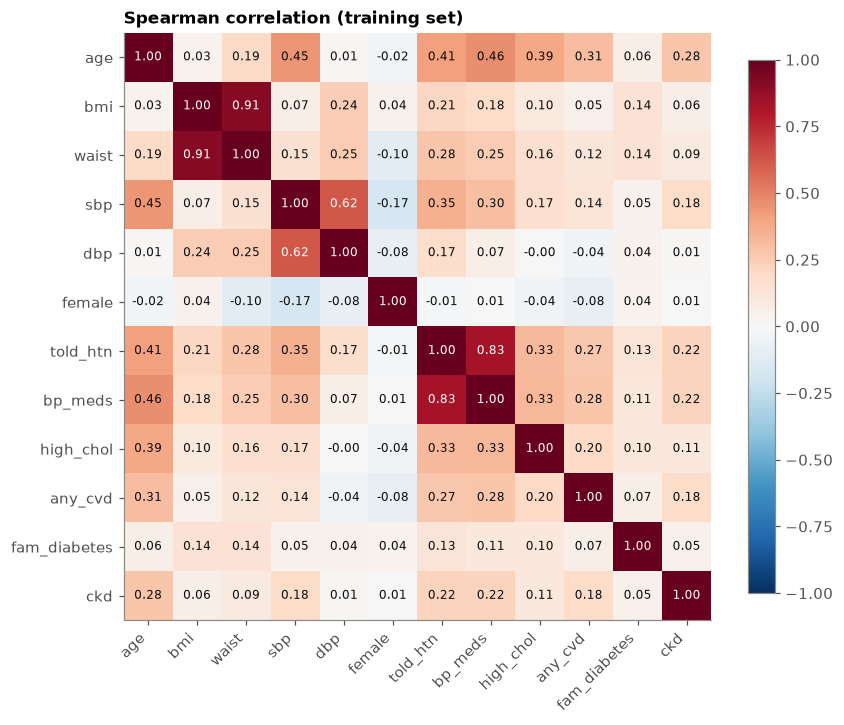

In [19]:
columns = nhanes.NUMERIC_FEATURES + nhanes.BINARY_FEATURES + ["ckd"]
corr = train[columns].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(columns)), columns, rotation=45, ha="right")
ax.set_yticks(range(len(columns)), columns)
for i in range(len(columns)):
    for j in range(len(columns)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.6 else plot_style.TEXT)
ax.grid(False)
ax.set_title("Spearman correlation (training set)")
fig.colorbar(image, ax=ax, shrink=0.8)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_05_correlation.png")
plt.show()

**Finding:** Two pairs are very strongly related: BMI and waist (0.91), and being told of high BP and taking BP medicine (0.83). Systolic and diastolic BP are moderately related (0.62). Age is linked to many features (0.45 with systolic BP, 0.46 with BP medicine, 0.39 with high cholesterol) but not to diastolic BP (0.01), which matches section 8.

In the bottom row, no feature has a correlation with CKD above 0.28 (age). No single feature carries the answer. That is what I would expect when no feature leaks the label, and it also means the model has to combine several weak signals.

**Action:** keep both features in each strongly related pair. Logistic Regression uses L2 regularization, which handles correlated features by sharing the weight between them, and the tree models are not affected. The cost is that the Logistic Regression coefficients for BMI and waist, and for the two BP questions, should not be interpreted one at a time.

## 11. Outliers

The usual box plot rule flags any value more than 1.5 times the interquartile range beyond the quartiles. That rule assumes a fairly symmetric distribution, so on skewed features like BMI it flags a lot of real people. The question for each flagged value is whether it is a **data error** or a **real extreme**. Section 5.5 already showed that nothing falls outside the plausible ranges.

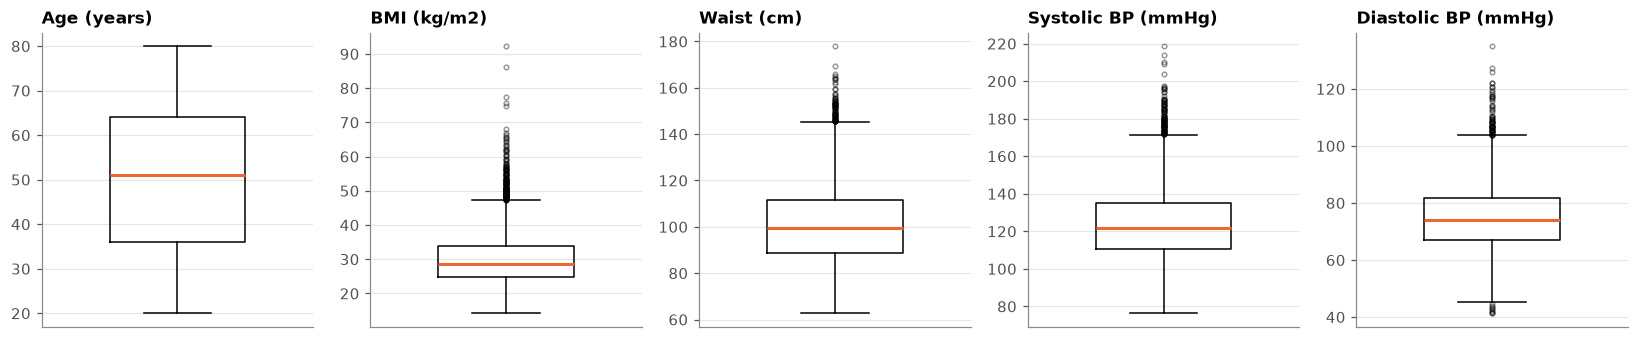

,feature,flagged by 1.5 IQR rule,lowest value,highest value,CKD rate among flagged
0,age,0,20.000,80.000,NaN
1,bmi,172,14.200,92.300,0.209
2,waist,71,62.700,178.000,0.197
3,sbp,104,76.333,218.667,0.462
4,dbp,73,41.333,135.000,0.384


In [20]:
rows = []
for column in nhanes.NUMERIC_FEATURES:
    q1, q3 = train[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (train[column] < low) | (train[column] > high)
    rows.append({"feature": column, "flagged by 1.5 IQR rule": flagged.sum(),
                 "lowest value": train[column].min(), "highest value": train[column].max(),
                 "CKD rate among flagged": train.loc[flagged, "ckd"].mean()})
outliers = pd.DataFrame(rows).round(3)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, column in zip(axes, nhanes.NUMERIC_FEATURES):
    ax.boxplot(train[column].dropna(), widths=0.5, flierprops={"markersize": 3, "alpha": 0.4},
               medianprops={"color": plot_style.CKD, "linewidth": 2})
    ax.set(title=titles[column], xticks=[])

fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_06_outliers.png")
plt.show()

outliers

**Finding:** The 1.5 IQR rule flags 172 BMI values, 104 systolic, 73 diastolic and 71 waist values. Section 5.5 already showed that all of them are inside the plausible range, so these are real people with extreme values, not errors. They also matter: 46% of the people flagged for systolic BP and 38% of those flagged for diastolic BP have CKD, compared with 16.5% overall.

**Action:** keep all outliers, with no capping or removal. Removing them would throw away the high-risk patients the model most needs to learn from. Tree models split on thresholds, so extreme values do not pull them. Logistic Regression is more sensitive to extremes, but these are a few hundred real values among thousands, and I prefer keeping them over inventing a cut-off.

## 12. Age is partly built into the label

The eGFR equation contains age: every extra year multiplies eGFR by 0.9938. So two people with the **same** creatinine get different eGFR values if their ages differ, and the older one is more likely to fall below 60. This means part of age's link with the label comes from how the label is calculated, not only from biology.

The plot shows eGFR against age for everyone in the training set, plus three curves from the equation for a man with a fixed creatinine of 1.0, 1.3 and 1.6 mg/dL.

**What to look at:** where each curve crosses the line at 60.

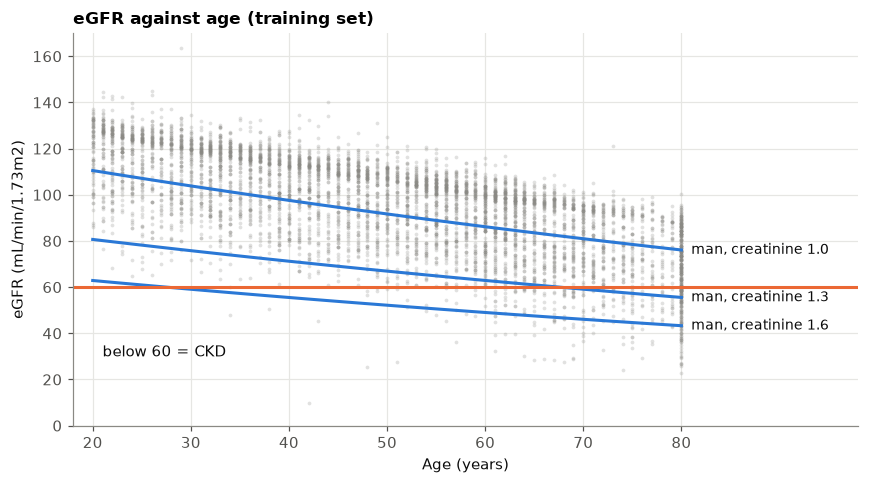

Median age of people labeled by low eGFR: 74
Share of them aged 60 or older: 91.9%


In [21]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(train["age"], train["egfr"], s=6, alpha=0.25, color=plot_style.AXIS, linewidths=0)

ages = np.arange(20, 81)
for creatinine in [1.0, 1.3, 1.6]:
    curve = nhanes.egfr_ckd_epi_2021(np.full(len(ages), creatinine), ages, np.zeros(len(ages), dtype=bool))
    ax.plot(ages, curve, color=plot_style.NO_CKD, linewidth=2)
    ax.text(81, curve[-1], f"man, creatinine {creatinine}", va="center", fontsize=9, color=plot_style.TEXT)

ax.axhline(60, color=plot_style.CKD, linewidth=2)
ax.text(21, 30, "below 60 = CKD", color=plot_style.TEXT)
ax.set(title="eGFR against age (training set)", xlabel="Age (years)",
       ylabel="eGFR (mL/min/1.73m2)", xlim=(18, 98), ylim=(0, 170), xticks=range(20, 81, 10))

fig.tight_layout()
fig.savefig(FIGURE_DIR / "nhanes_07_age_in_label.png")
plt.show()

low_egfr_cases = train[train["low_egfr"] == 1]
print(f"Median age of people labeled by low eGFR: {low_egfr_cases['age'].median():.0f}")
print(f"Share of them aged 60 or older: {(low_egfr_cases['age'] >= 60).mean():.1%}")

**Finding:** The curves show how much age alone moves eGFR. A man with creatinine 1.3 mg/dL stays above 60 until about age 67 and drops below it after that. With the exact same blood test, he is labeled "no CKD" at 65 and "CKD" at 70. A man with creatinine 1.6 is below 60 from about age 28. Among people labeled because of low eGFR, the median age is 74 and 91.9% are 60 or older. The vertical band of points at 80 is the top-coding again.

**Action:** no change to the label, because eGFR really does decline with age and age is known before any test. But I expect age to be the most important feature in every model, and the paper has to say that part of that importance comes from the label's formula and not only from biology. It also means low-eGFR CKD in younger adults will be hard to catch with these features.

## 13. Is a missing value itself a signal?

If people with a missing measurement have a different CKD rate from people without, the fact that it is missing carries information. The modeling pipeline could keep that information with a "was missing" indicator column. Before doing that, I need to ask whether the reason for the missing value would be the same in real use.

In [22]:
rows = []
for column in ["sbp", "waist", "bmi"]:
    is_missing = train[column].isna()
    rows.append({"feature": column, "missing": is_missing.sum(),
                 "CKD rate if missing": train.loc[is_missing, "ckd"].mean(),
                 "CKD rate if measured": train.loc[~is_missing, "ckd"].mean(),
                 "median age if missing": train.loc[is_missing, "age"].median()})
pd.DataFrame(rows).round(3)

,feature,missing,CKD rate if missing,CKD rate if measured,median age if missing
0,sbp,530,0.198,0.162,49.0
1,waist,212,0.316,0.160,57.5
2,bmi,62,0.339,0.164,54.5


**Finding:** Missing values are not random. People with no waist measurement have CKD about twice as often (31.6% vs 16.0%). The same is true for BMI (33.9% vs 16.4%), although that is only 62 people. People without a BP reading have slightly more CKD (19.8% vs 16.2%).

NHANES records 207 of the 271 missing waist values in the cohort as "could not obtain", meaning the examiner tried but could not take the measurement. NHANES does not record why. My interpretation is that these are often people who could not stand or be measured properly, which itself points to poorer health.

**Action:** I will **not** add "was missing" indicator columns, even though they would probably raise the scores a little. In the app, a missing waist will mean the health worker skipped it or had no tape measure, which says nothing about the patient's health. A model that learned "missing waist means higher risk" from NHANES would give wrong answers in real use. Plain median filling is used instead, and the app will ask for blood pressure, which every health unit can measure.

## 14. Subgroups

The app is meant for Filipino patients, but NHANES is a US survey. The closest group available is Non-Hispanic Asian (`RIDRETH3` = 6). This is not the same as a Filipino population, but it is the best check available. Race is never used as a model input (see the pre-registration). It is only used here and in the final subgroup check.

In [23]:
groups = {1: "Mexican American", 2: "Other Hispanic", 3: "Non-Hispanic White",
          4: "Non-Hispanic Black", 6: "Non-Hispanic Asian", 7: "Other or multiracial"}
subgroups = train.groupby(train["RIDRETH3"].map(groups))["ckd"].agg(people="size", ckd_cases="sum", prevalence="mean")
subgroups.round(3)

,people,ckd_cases,prevalence
RIDRETH3,,,
Mexican American,735,108,0.147
Non-Hispanic Asian,724,94,0.130
Non-Hispanic Black,1455,270,0.186
Non-Hispanic White,2055,361,0.176
Other Hispanic,643,83,0.129
Other or multiracial,278,58,0.209


**Finding:** CKD prevalence ranges from 12.9% (Other Hispanic) to 20.9% (Other or multiracial). Non-Hispanic Asian is 13.0%, with 724 people and 94 cases in the training set. The test set is a quarter the size of the training set, so it should contain only about 180 Non-Hispanic Asian participants and roughly 24 cases.

**Action:** the subgroup result on the test set will be reported with that caveat. With so few cases its numbers will be very uncertain, so it is a rough check, not a firm estimate.

## 15. EDA summary: findings and the decisions they lead to

| What the EDA found | Decision it leads to |
|---|---|
| 16.5% have CKD, about 5 to 1 | F2 as primary metric, `class_weight="balanced"`, stratified split and folds. Refer-everyone F2 = 0.50 is the floor to beat. |
| Codes 7 and 9 in 12 of 15 questions, most in family history of diabetes (102) | Recoded to missing and filled in inside the pipeline. The app accepts "don't know". |
| Skip-pattern blanks in smoking and BP medicine | Read as known answers (never smoker, not taking medicine), not as missing |
| No impossible values. Outliers are real and higher risk | Keep all outliers. The same plausible ranges validate app input. |
| BP missing 9.0%, waist 3.7%, everything else under 1.5% | Keep every feature. Median / most common answer filled in inside the pipeline. |
| Missing waist and BMI linked to CKD, for a reason that will not hold in the app | No "was missing" indicator columns |
| BMI and waist 0.91, told high BP and BP medicine 0.83 | Keep both. L2 regularization for Logistic Regression. Do not read those coefficients one at a time. |
| No feature correlates with CKD above 0.28 | No sign of leakage. Expect moderate performance from combining weak signals. |
| Age is the strongest feature and partly built into the label | Expect age to dominate and say so in the paper. Young low-eGFR CKD will be hard to catch. |
| Smoking is confounded by age | Raw rates are not effects. The models see both features together. |
| Most CKD is albuminuria only | Most cases are early disease. The single-measurement limitation goes in the paper. |
| People without labs were slightly higher risk | Limitation: prevalence is probably slightly underestimated |
| BMI is right-skewed | No transform. Numeric features are scaled for Logistic Regression. |
| Non-Hispanic Asian group is small in the test set | Subgroup result reported as a rough check only |

**Preprocessing pipeline that follows from this**, identical for all three models and fit on training folds only:

- numeric (age, bmi, waist, sbp, dbp): median imputation, then standard scaling
- yes/no (female, told_htn, bp_meds, high_chol, any_cvd, fam_diabetes): most-common-answer imputation
- categorical (diabetes, smoking): most-common-answer imputation, then one-hot encoding